Partially moved to snakemake!

In [2]:
suppressMessages(library('CRISPRcleanR'))

# Our data (moved to snakemake)

In [45]:
# ['H1975', 'H1299', 'A549']
cell_line <- 'H1975'

In [46]:
libraryAnnotation <- read.table('../results/tables/guide_alignment_genome_annotated_for_crisprcleanr.csv', header = TRUE, sep = ",", row.names = 1)
counts_file <- paste0('/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/pooled_screen_1_counts_for_cleaner_TP6_', cell_line, '.tsv')

In [47]:
head(libraryAnnotation)

,GENES,CHRM,STARTpos,ENDpos,STRAND,EXONE,seq
,<chr>,<chr>,<int>,<int>,<chr>,<int>,<chr>
CYP26B1_ENST00000001146_2702,CYP26B1,2,72131268,72131291,sense,6,TTAAACCCAAATAATGCCCGGAG
RPS20_ENST00000009589_544,RPS20,8,56073029,56073052,sense,4,TATTCTGAATAAAAACCAACAGA
NDUFAB1_ENST00000007516_654,NDUFAB1,16,23581065,23581088,sense,4,AAGTCCATCAGAATCACTCTGTC
COX15_ENST00000016171_2286,COX15,10,99713585,99713608,sense,9,ATTACAAAGCTGTTAGGAAACCC
AQR_ENST00000156471_5156,AQR,15,34856320,34856343,sense,35,AATATCTTTACATAAAGACAGCA
NDUFAB1_ENST00000007516_667,NDUFAB1,16,23581052,23581075,sense,4,ACAATTTAAATACAAGTCCATCA


In [49]:
## Loading, median-normalizing and computing fold-changes
normANDfcs <- ccr.NormfoldChanges(
    filename = counts_file,
    display = TRUE,
    min_reads = 30,
    ncontrols = 3,
    EXPname = cell_line,
    saveToFig = TRUE,
    outdir = '/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/',
    libraryAnnotation = libraryAnnotation
)

In [50]:
## Genome-sorting the fold changes
gwSortedFCs <- ccr.logFCs2chromPos(
    foldchanges = normANDfcs$logFCs,
    libraryAnnotation = libraryAnnotation
)

In [53]:
## Identifying and correcting biased sgRNAs' fold changes
correctedFCs_and_segments <- suppressWarnings(ccr.GWclean(
    gwSortedFCs = gwSortedFCs,
    display=TRUE,
    label=cell_line,
    saveTO='/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/'
))

Analyzing: H1975.Chr.1.sgRNA.FCs 
Analyzing: H1975.Chr.1.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.2.sgRNA.FCs 
Analyzing: H1975.Chr.2.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.3.sgRNA.FCs 
Analyzing: H1975.Chr.3.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.4.sgRNA.FCs 
Analyzing: H1975.Chr.4.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.5.sgRNA.FCs 
Analyzing: H1975.Chr.5.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.6.sgRNA.FCs 
Analyzing: H1975.Chr.6.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.7.sgRNA.FCs 
Analyzing: H1975.Chr.7.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.8.sgRNA.FCs 
Analyzing: H1975.Chr.8.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.9.sgRNA.FCs 
Analyzing: H1975.Chr.9.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.10.sgRNA.FCs 
Analyzing: H1975.Chr.10.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.11.sgRNA.FCs 
Analyzing: H1975.Chr.11.sgRNA.FCs...post.CRISPRcleanR 
Analyzing: H1975.Chr.12.sgRN

In [55]:
names(correctedFCs_and_segments)

[1] "corrected_logFCs" "SORTED_sgRNAs"    "segments"

In [60]:
write.csv(correctedFCs_and_segments$corrected_logFCs, file = paste0('/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/', cell_line, '_corrected_logFCs.csv'))
write.csv(correctedFCs_and_segments$segments, file = paste0('/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/', cell_line, '_segments.csv'))
write.csv(correctedFCs_and_segments$SORTED_sgRNAs, file = paste0('/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/', cell_line, '_SORTED_sgRNAs.csv'))

# Brunello Example

In [61]:
## Not run:
## Loading sgRNA Brunello library annotation file
data(Brunello_Library)
## Visualising first entries
head(Brunello_Library)

,CODE,Target.Gene.ID,GENES,Target.Transcript,Genomic.Sequence,STARTpos,STRAND,Target.Context.Sequence,PAM.Sequence,EXONE,Rule.Set.2.score,CHRM,ENDpos,seq
,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<dbl>,<chr>,<dbl>,<chr>
A1BG_1,A1BG_1,1,A1BG,NM_130786.3,NC_000019.10,58351502,sense,ATCGCATCTTCTTTCACCTGAACGCGGTGG,CGG,5,0.6165,19,58351522,ATCGCATCTTCTTTCACCTGAACGCGGTGG
A1BG_2,A1BG_2,1,A1BG,NM_130786.3,NC_000019.10,58350637,antisense,CCGGCTCCGGGGAGAACTCCGGCGCGGGCA,CGG,6,0.6176,19,58350657,CCGGCTCCGGGGAGAACTCCGGCGCGGGCA
A1BG_3,A1BG_3,1,A1BG,NM_130786.3,NC_000019.10,58351668,antisense,GGACTCTCCATGGTGCATCAGCACAGGCGG,AGG,5,0.5264,19,58351688,GGACTCTCCATGGTGCATCAGCACAGGCGG
A1BG_4,A1BG_4,1,A1BG,NM_130786.3,NC_000019.10,58351593,antisense,TAGCTGGAAGTCCACTCCACTCAGGGGAGC,GGG,5,0.7156,19,58351613,TAGCTGGAAGTCCACTCCACTCAGGGGAGC
A2M_5,A2M_5,2,A2M,NM_000014.4,NC_000012.12,9090399,sense,CCTCACTGCATCTGTGCAAACGGGCGGCAA,CGG,20,0.6765,12,9090419,CCTCACTGCATCTGTGCAAACGGGCGGCAA
A2M_6,A2M_6,2,A2M,NM_000014.4,NC_000012.12,9101535,sense,GCCCATGTCTCATGAACTACCCTGTGGCCA,TGG,12,0.7487,12,9101555,GCCCATGTCTCATGAACTACCCTGTGGCCA


In [62]:
## Deriving the path of an example count file
## from screening the HT-29 cell line with the Brunello library
## [2]
fn<-paste(system.file('extdata', package = 'CRISPRcleanR'),'/HT29-Brunello_counts.tsv', sep='')
expName<-'HT29-Brunello'

In [63]:
counts = read.table(fn, header = TRUE, sep = "\t", row.names = 1)

In [64]:
head(counts)

,gene,Brunello_plasmid,Brunello_HT29.rep1,Brunello_HT29.rep2,Brunello_HT29.rep3
,<chr>,<int>,<int>,<int>,<int>
A1BG_1,A1BG,674,811,557,523
A1BG_2,A1BG,638,526,776,544
A1BG_3,A1BG,8,0,0,6
A1BG_4,A1BG,615,1177,634,532
A2M_5,A2M,393,469,545,416
A2M_6,A2M,731,764,783,605


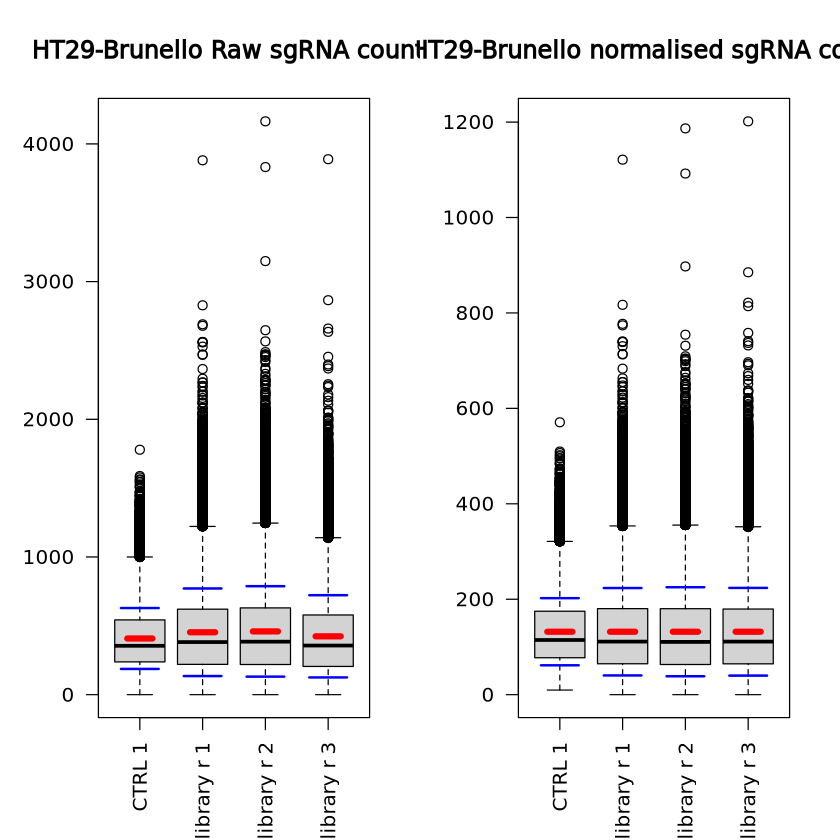

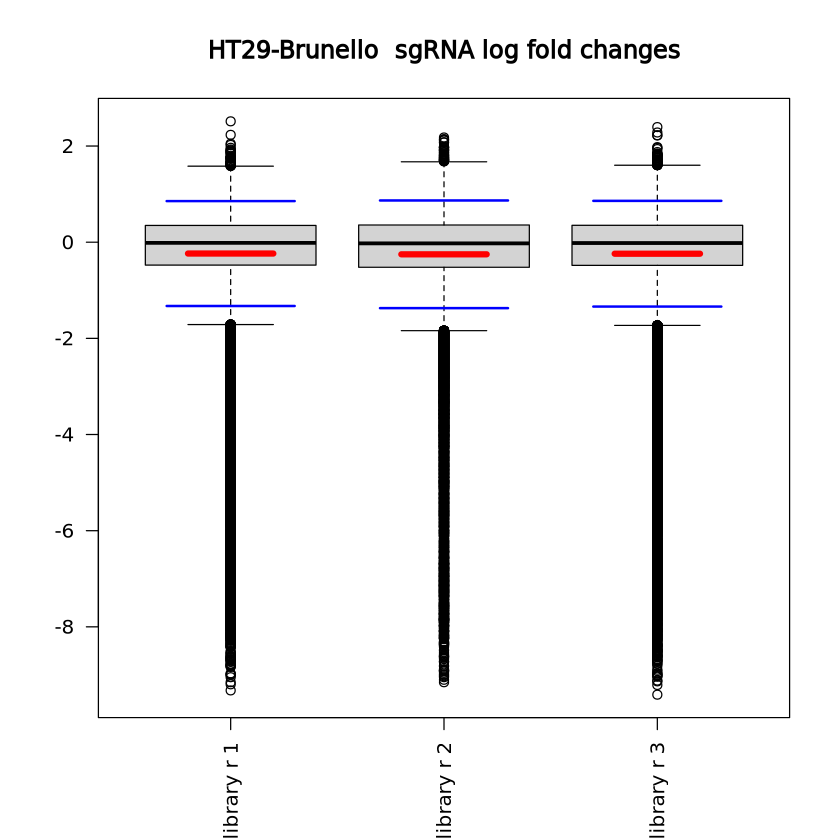

In [65]:
## Loading, median-normalizing and computing fold-changes
normANDfcs<-
ccr.NormfoldChanges(filename = fn,
display = TRUE,
min_reads = 30,
EXPname = expName,
libraryAnnotation = Brunello_Library)

In [66]:
## Genome-sorting the fold changes
gwSortedFCs<-
ccr.logFCs2chromPos(foldchanges = normANDfcs$logFCs,
libraryAnnotation = Brunello_Library)

Warning message in CNA(cbind(gwSortedFCs[["avgFC"]]), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


Analyzing: HT29.Brunello.Chr.1.sgRNA.FCs 


Warning message in CNA(cbind(newFC), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


Analyzing: HT29.Brunello.Chr.1.sgRNA.FCs...post.CRISPRcleanR 


Warning message in CNA(cbind(gwSortedFCs[["avgFC"]]), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


Analyzing: HT29.Brunello.Chr.2.sgRNA.FCs 


Warning message in CNA(cbind(newFC), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


Analyzing: HT29.Brunello.Chr.2.sgRNA.FCs...post.CRISPRcleanR 


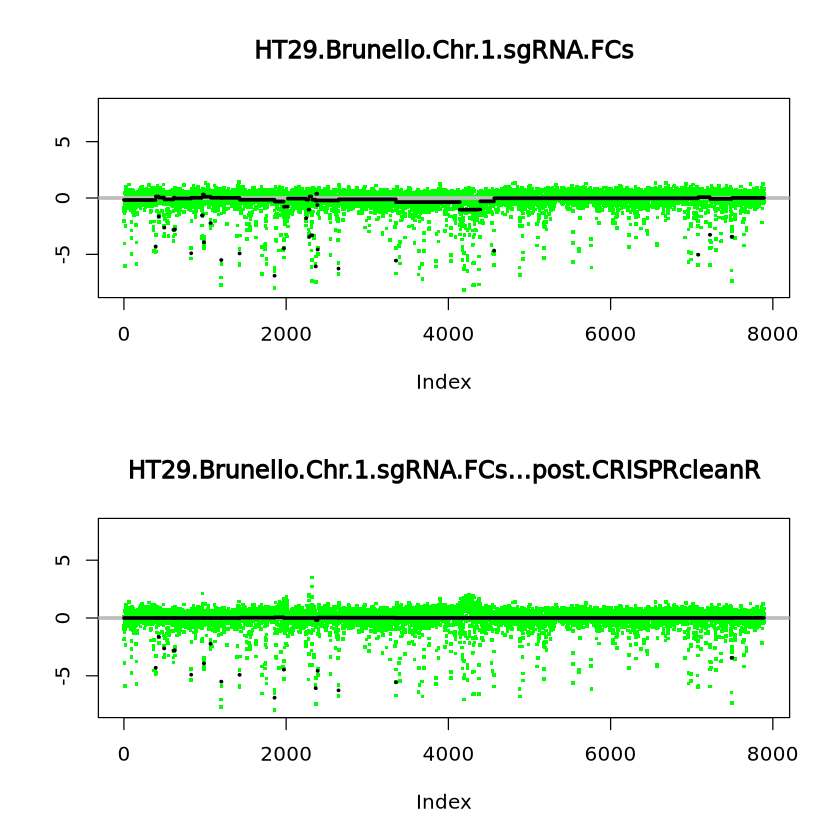

Analyzing: HT29.Brunello.Chr.3.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.3.sgRNA.FCs...post.CRISPRcleanR 


Warning message in CNA(cbind(gwSortedFCs[["avgFC"]]), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


Analyzing: HT29.Brunello.Chr.4.sgRNA.FCs 


Warning message in CNA(cbind(newFC), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


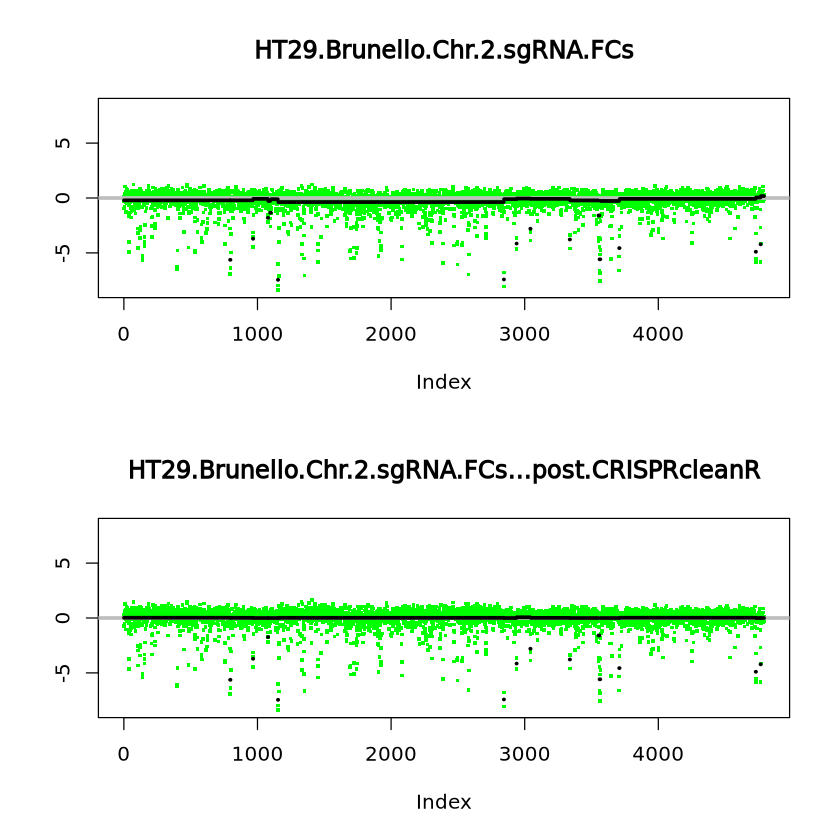

Analyzing: HT29.Brunello.Chr.4.sgRNA.FCs...post.CRISPRcleanR 


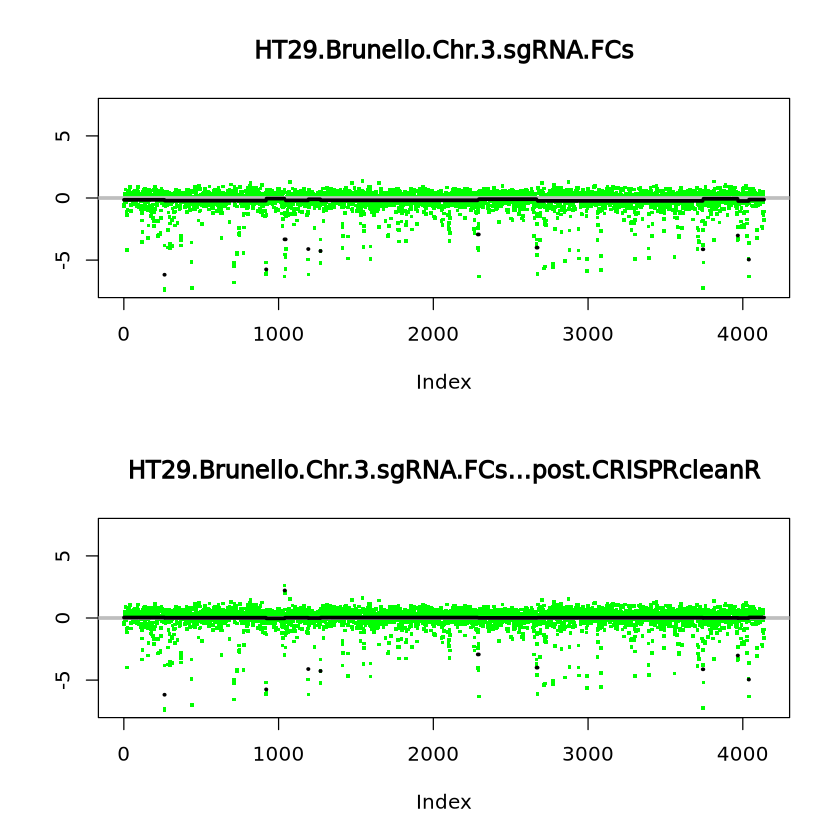

Analyzing: HT29.Brunello.Chr.5.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.5.sgRNA.FCs...post.CRISPRcleanR 


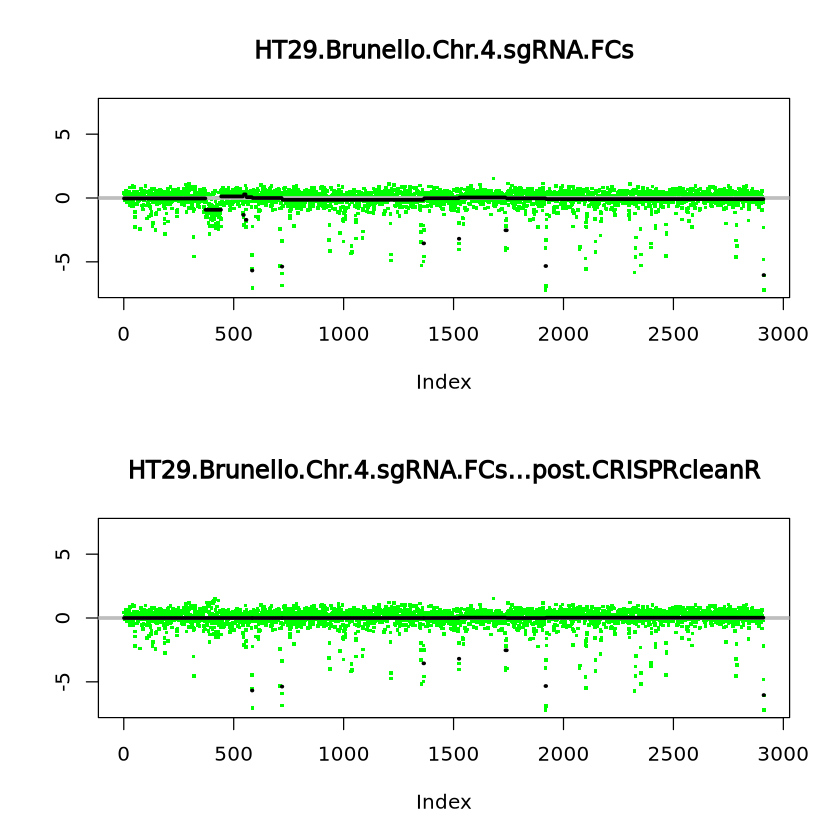

Analyzing: HT29.Brunello.Chr.6.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.6.sgRNA.FCs...post.CRISPRcleanR 


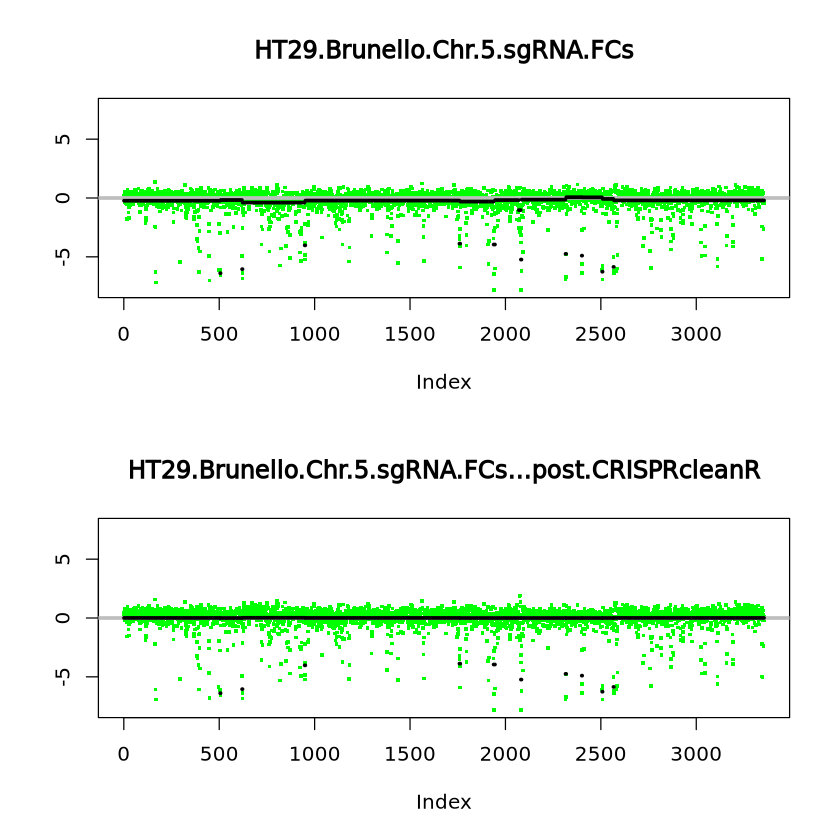

Analyzing: HT29.Brunello.Chr.7.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.7.sgRNA.FCs...post.CRISPRcleanR 


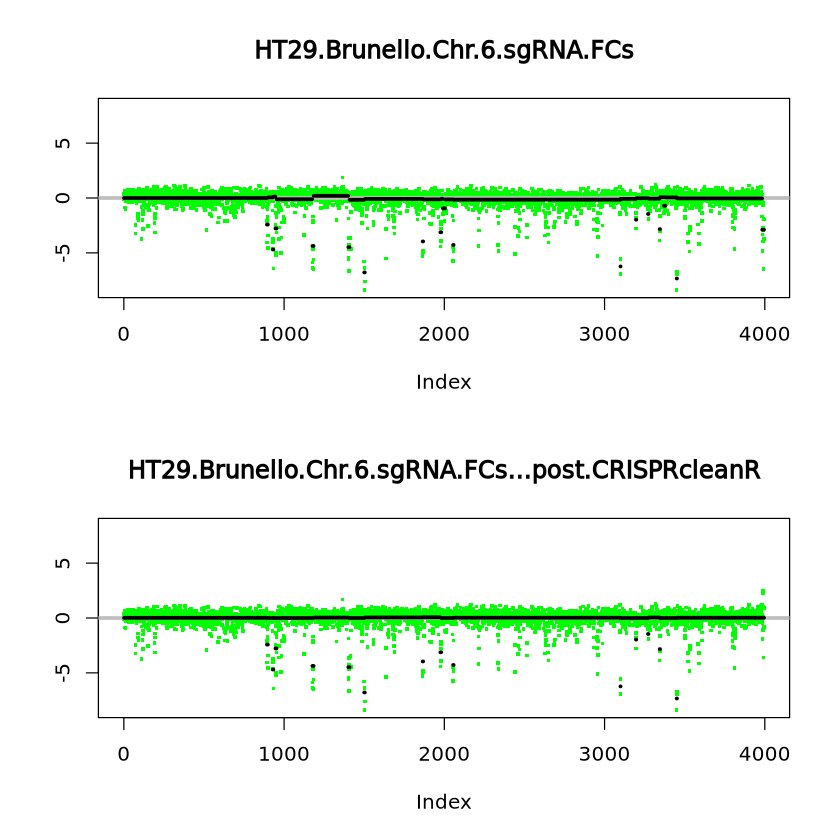

Analyzing: HT29.Brunello.Chr.8.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.8.sgRNA.FCs...post.CRISPRcleanR 


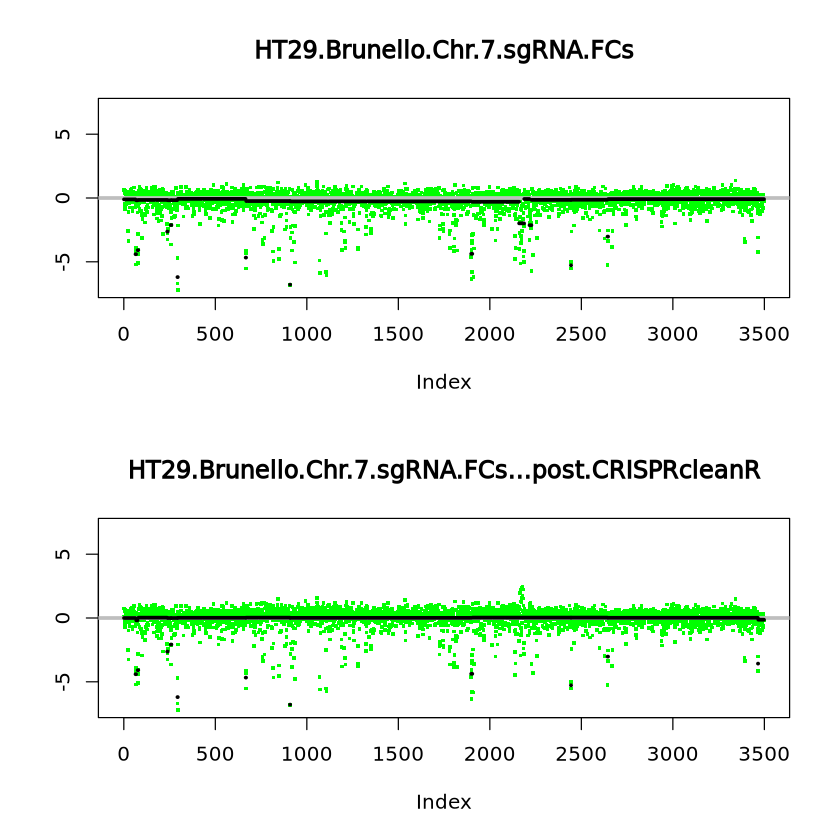

Analyzing: HT29.Brunello.Chr.9.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.9.sgRNA.FCs...post.CRISPRcleanR 


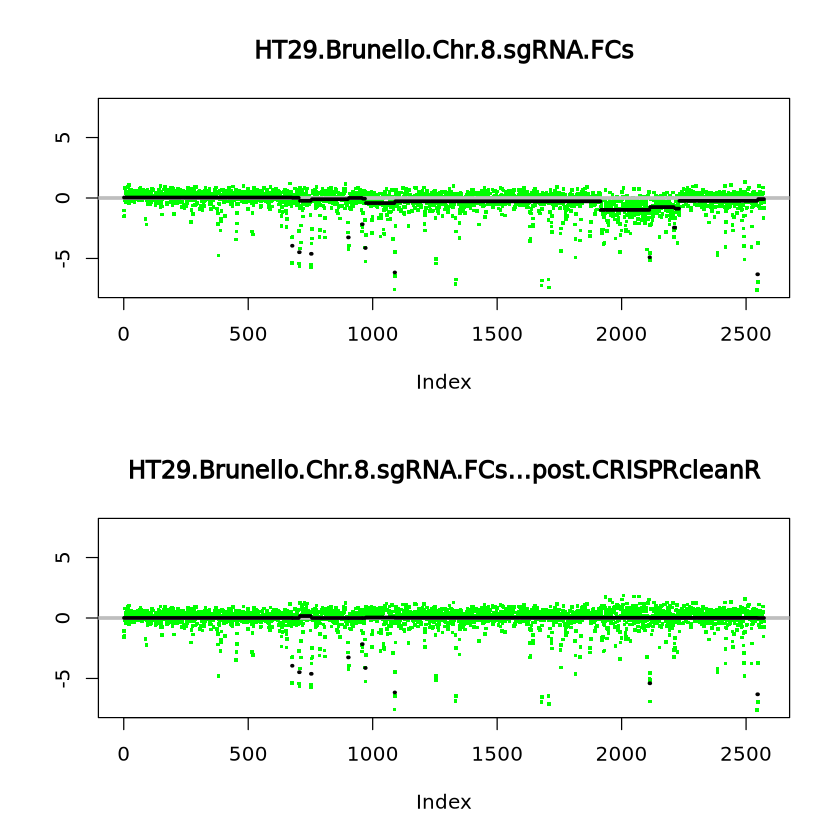

Analyzing: HT29.Brunello.Chr.10.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.10.sgRNA.FCs...post.CRISPRcleanR 


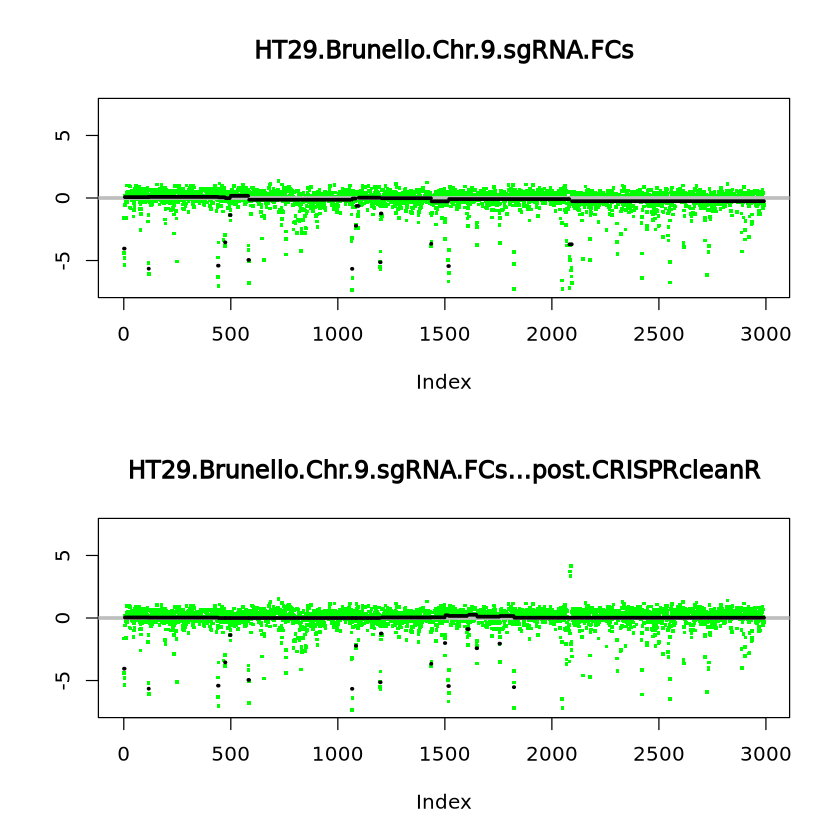

Analyzing: HT29.Brunello.Chr.11.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.11.sgRNA.FCs...post.CRISPRcleanR 


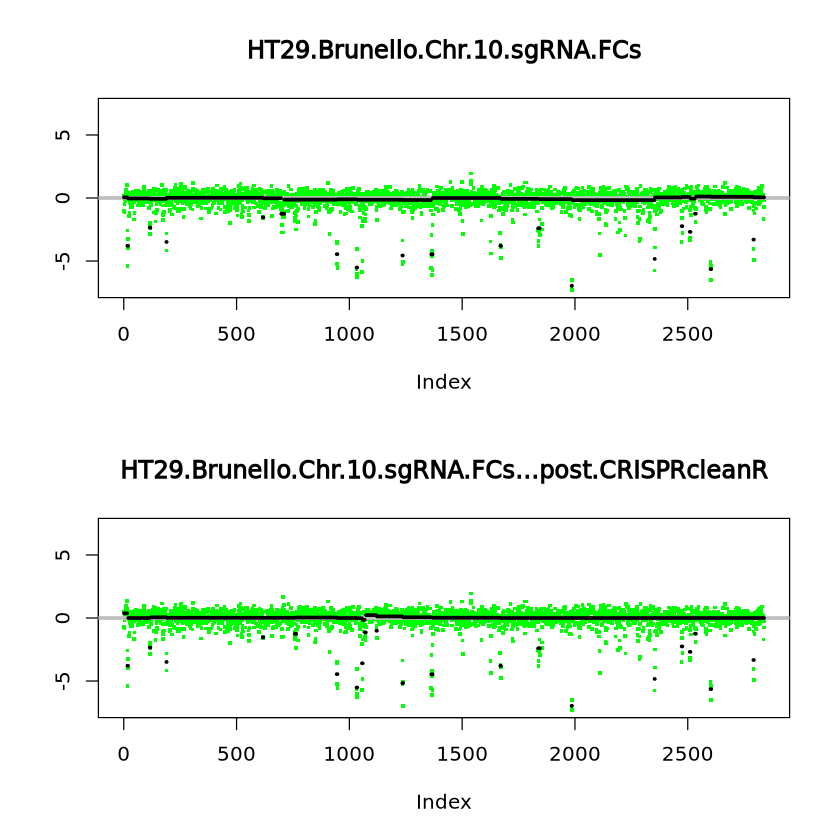

Analyzing: HT29.Brunello.Chr.12.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.12.sgRNA.FCs...post.CRISPRcleanR 


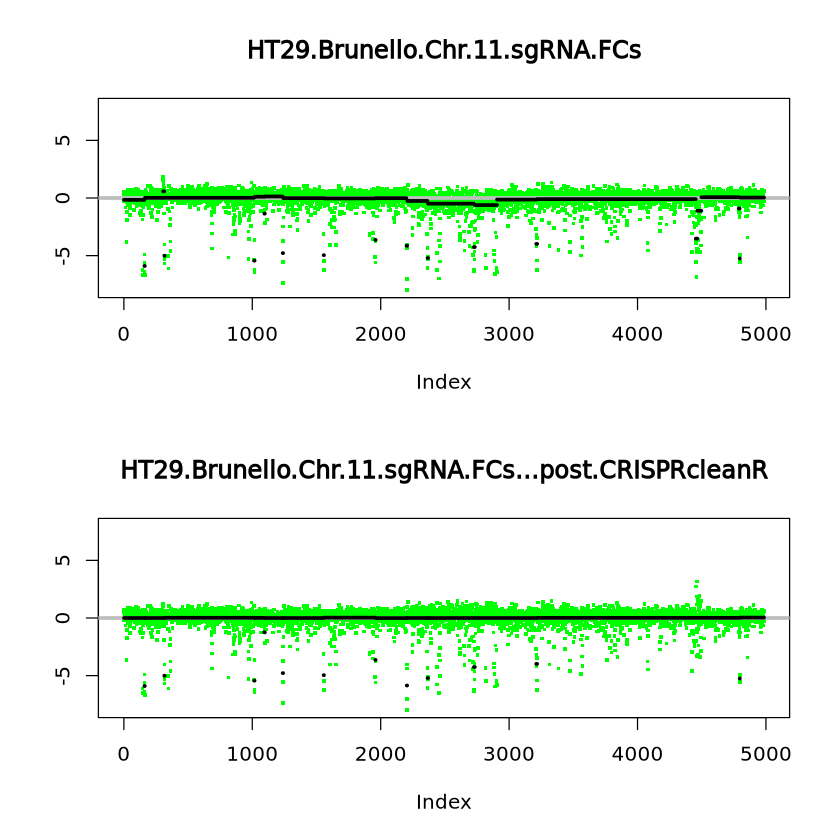

Analyzing: HT29.Brunello.Chr.13.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.13.sgRNA.FCs...post.CRISPRcleanR 


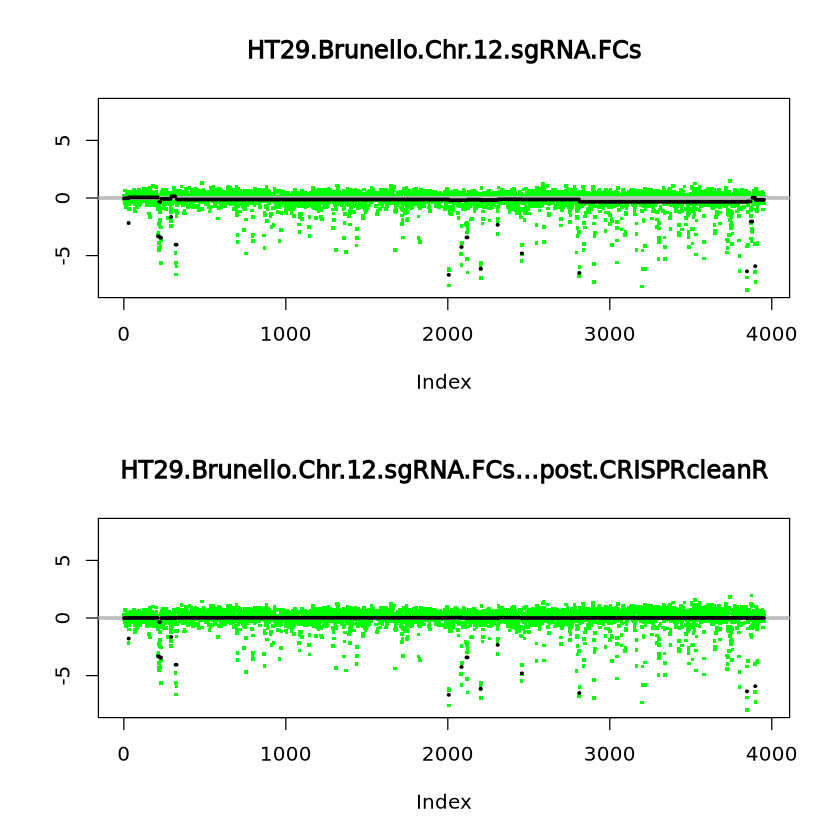

Analyzing: HT29.Brunello.Chr.14.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.14.sgRNA.FCs...post.CRISPRcleanR 


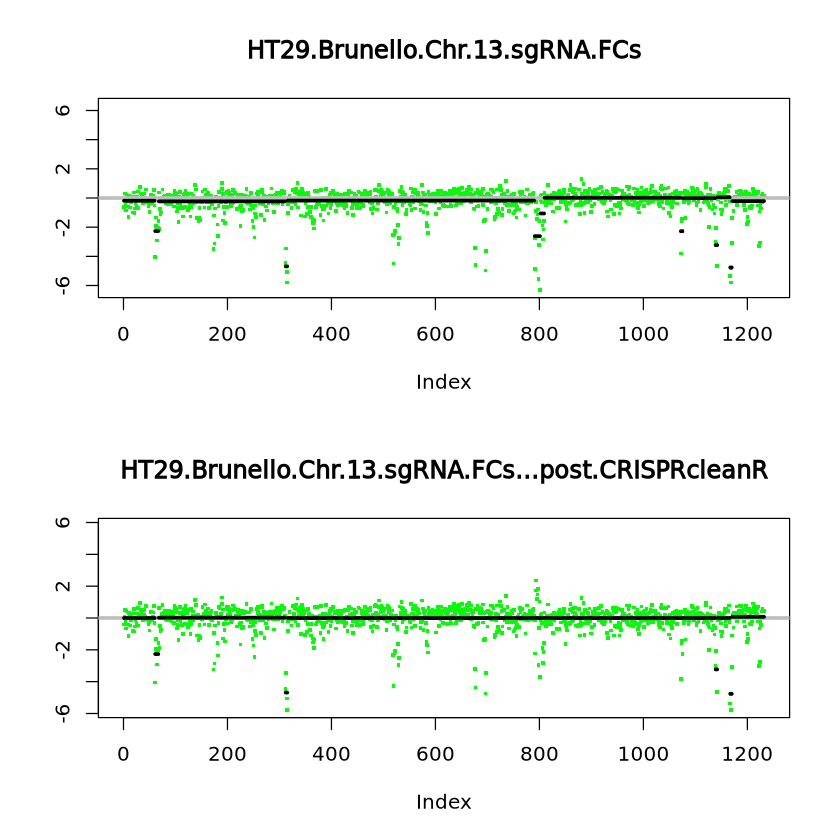

Analyzing: HT29.Brunello.Chr.15.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.15.sgRNA.FCs...post.CRISPRcleanR 


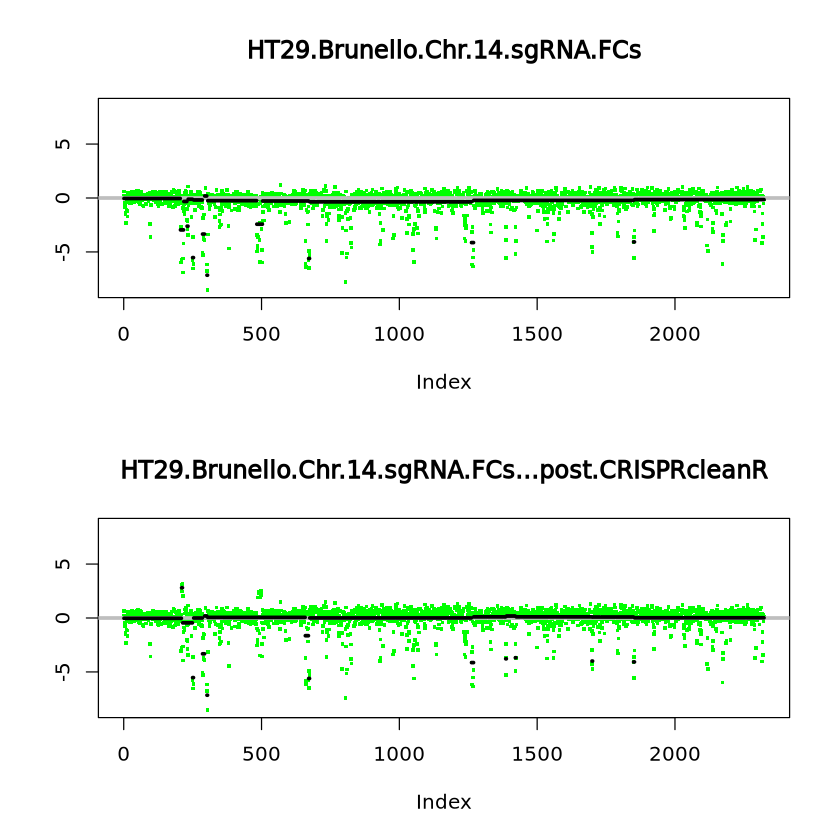

Analyzing: HT29.Brunello.Chr.16.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.16.sgRNA.FCs...post.CRISPRcleanR 


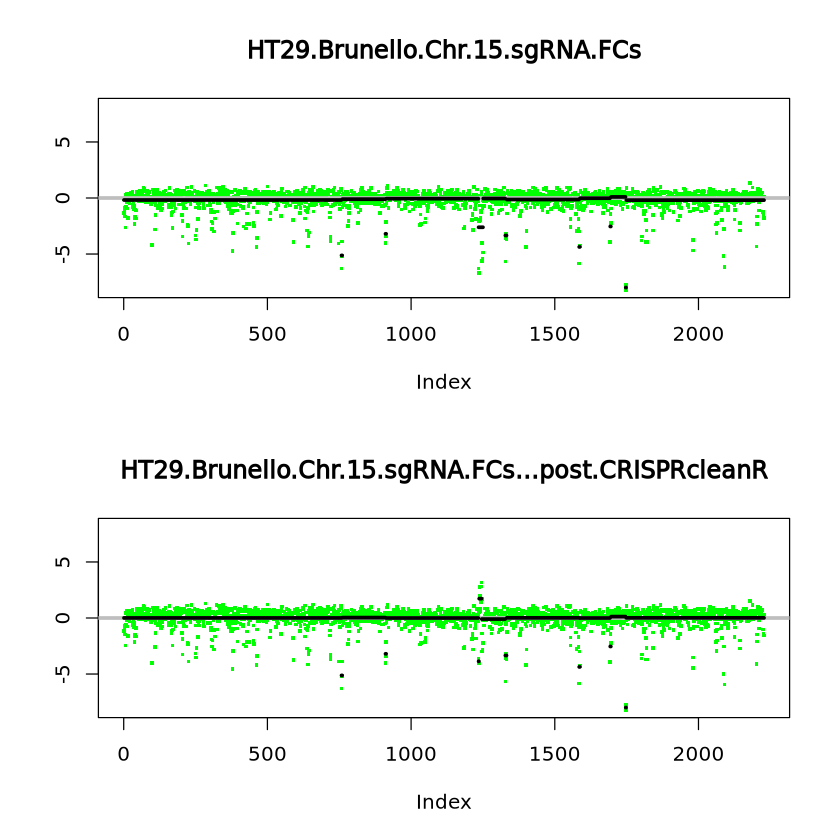

Analyzing: HT29.Brunello.Chr.17.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.17.sgRNA.FCs...post.CRISPRcleanR 


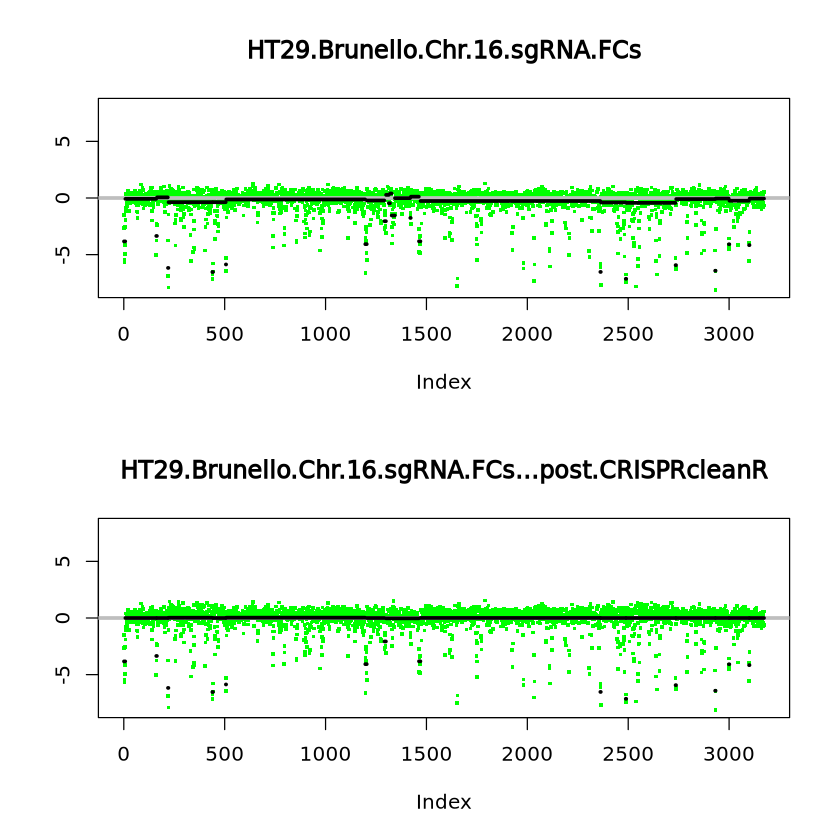

Analyzing: HT29.Brunello.Chr.18.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.18.sgRNA.FCs...post.CRISPRcleanR 


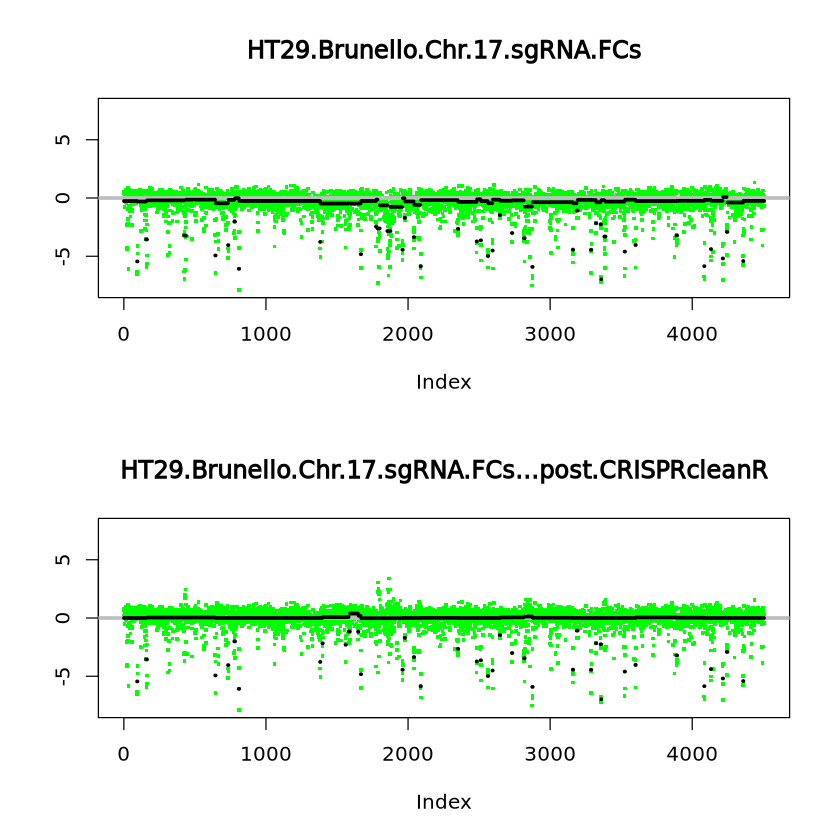

Analyzing: HT29.Brunello.Chr.19.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.19.sgRNA.FCs...post.CRISPRcleanR 


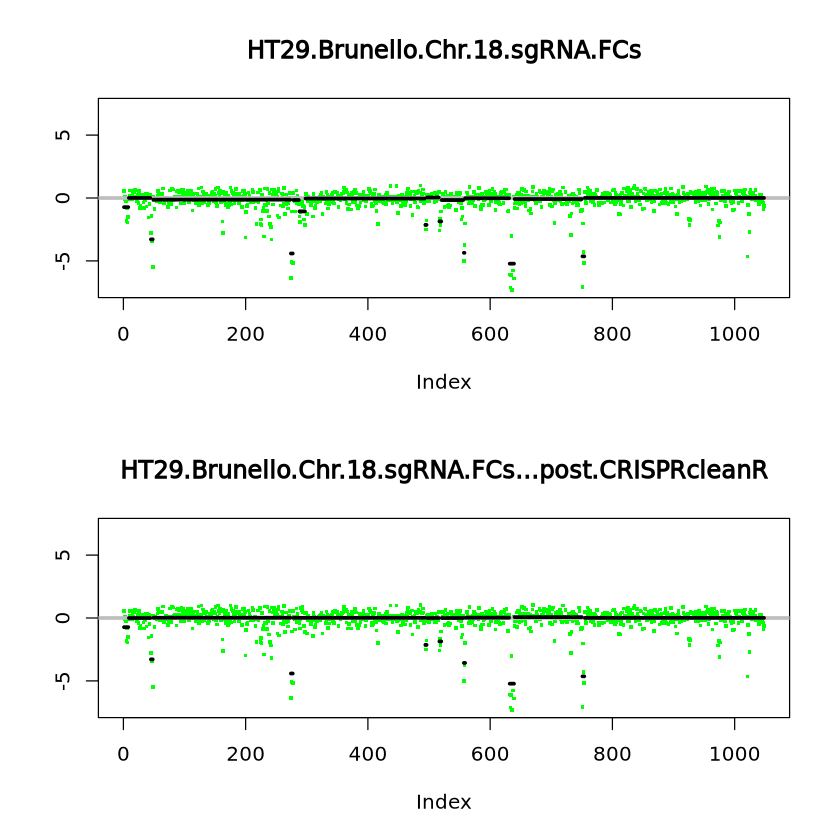

Analyzing: HT29.Brunello.Chr.20.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.20.sgRNA.FCs...post.CRISPRcleanR 


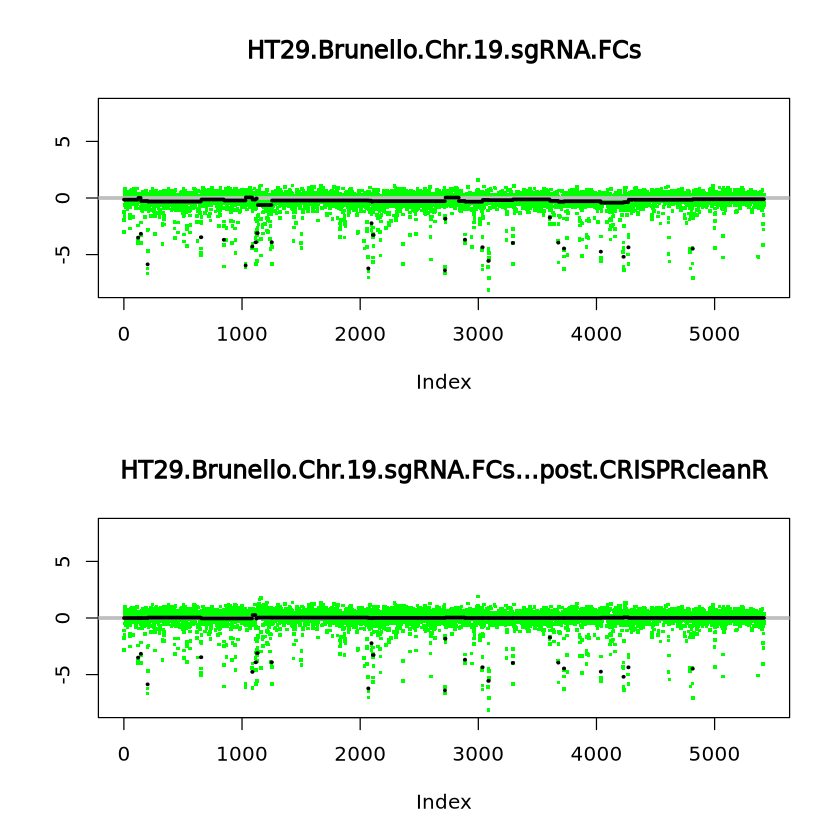

Analyzing: HT29.Brunello.Chr.21.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.21.sgRNA.FCs...post.CRISPRcleanR 


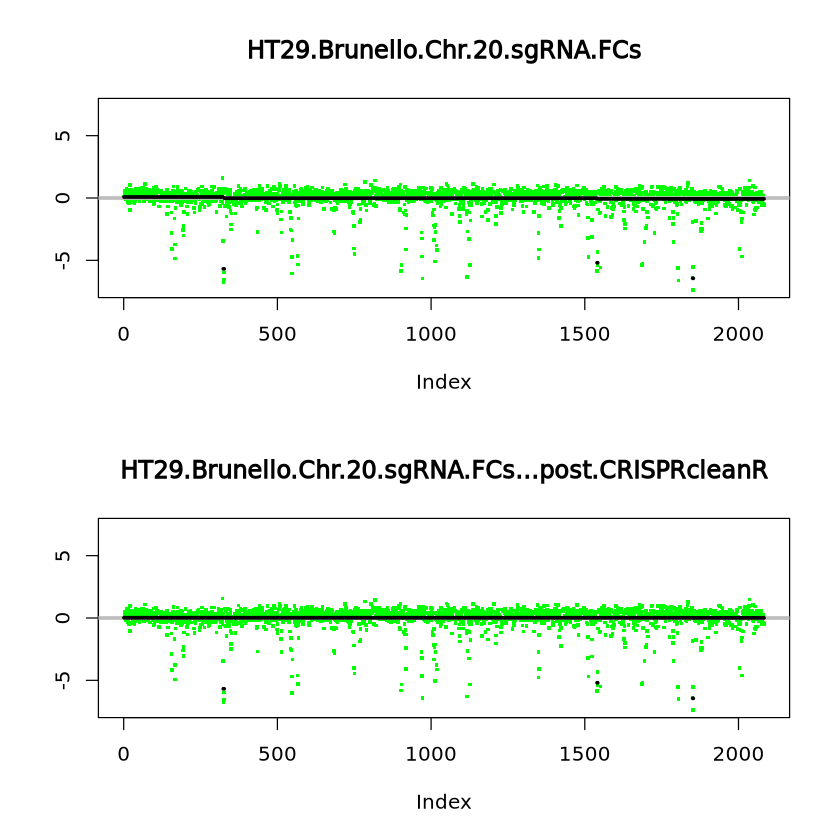

Analyzing: HT29.Brunello.Chr.22.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.22.sgRNA.FCs...post.CRISPRcleanR 


Warning message in CNA(cbind(gwSortedFCs[["avgFC"]]), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


Analyzing: HT29.Brunello.Chr.23.sgRNA.FCs 


Warning message in CNA(cbind(newFC), gwSortedFCs[["CHR"]], gwSortedFCs[["BP"]], :
"array has repeated maploc positions
"


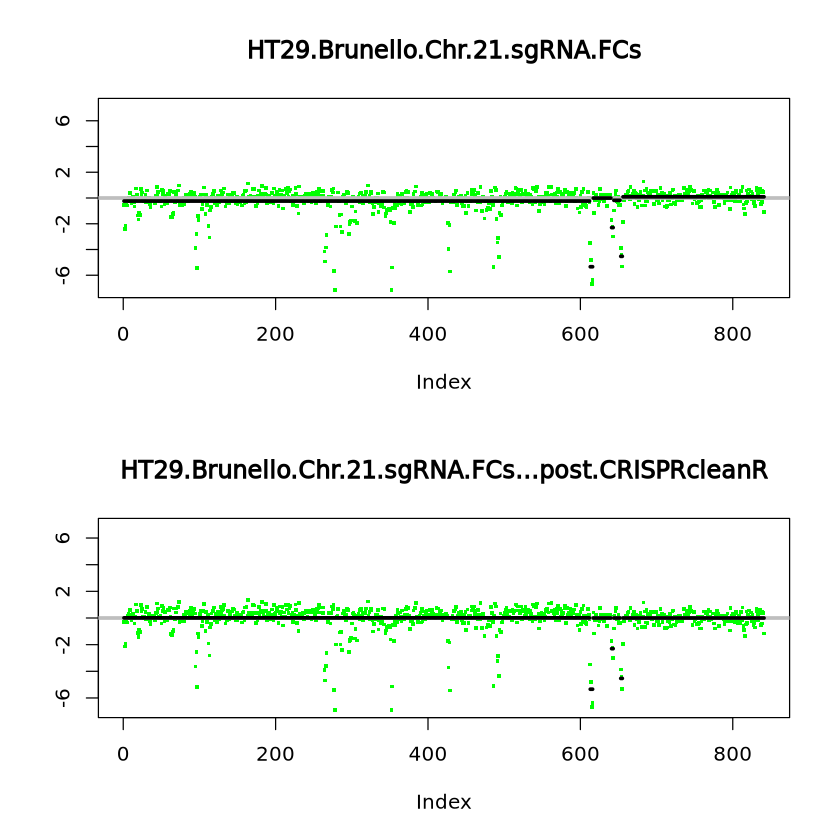

Analyzing: HT29.Brunello.Chr.23.sgRNA.FCs...post.CRISPRcleanR 


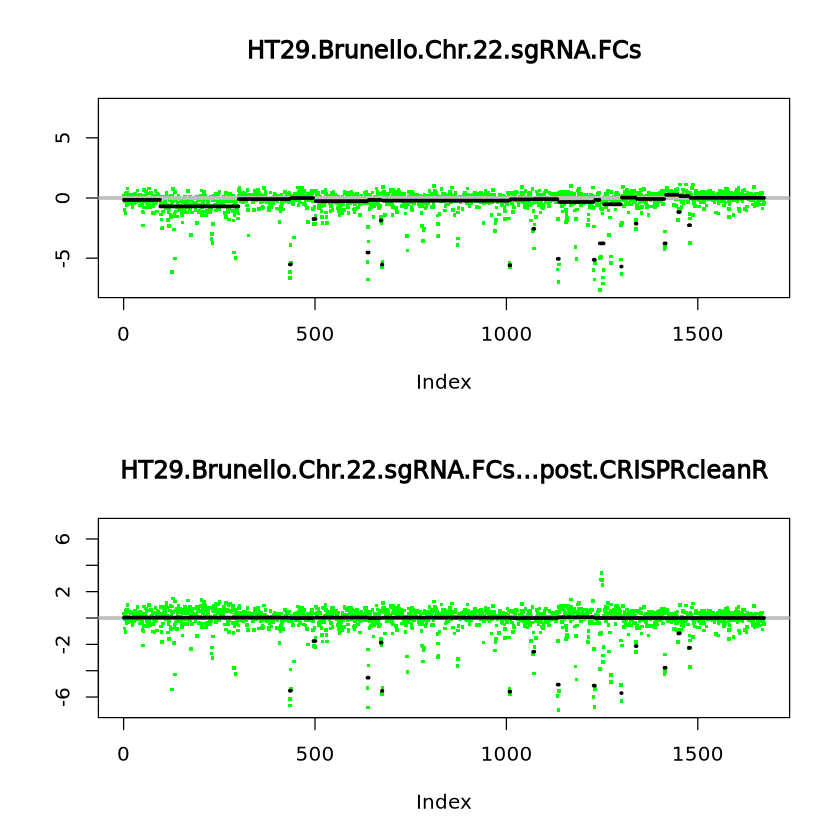

Analyzing: HT29.Brunello.Chr.24.sgRNA.FCs 
Analyzing: HT29.Brunello.Chr.24.sgRNA.FCs...post.CRISPRcleanR 


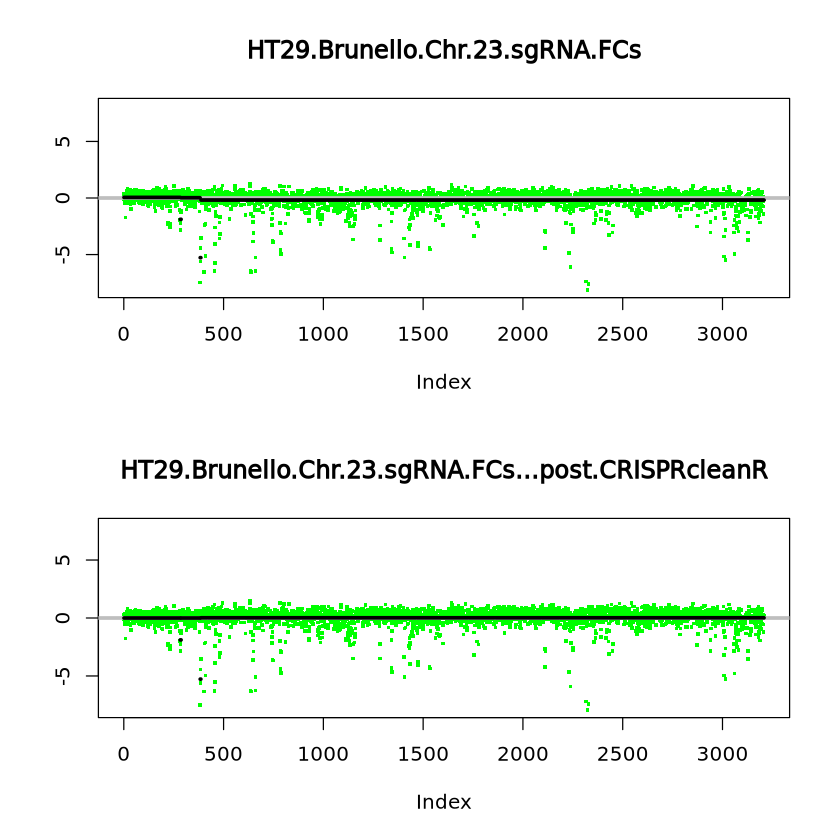

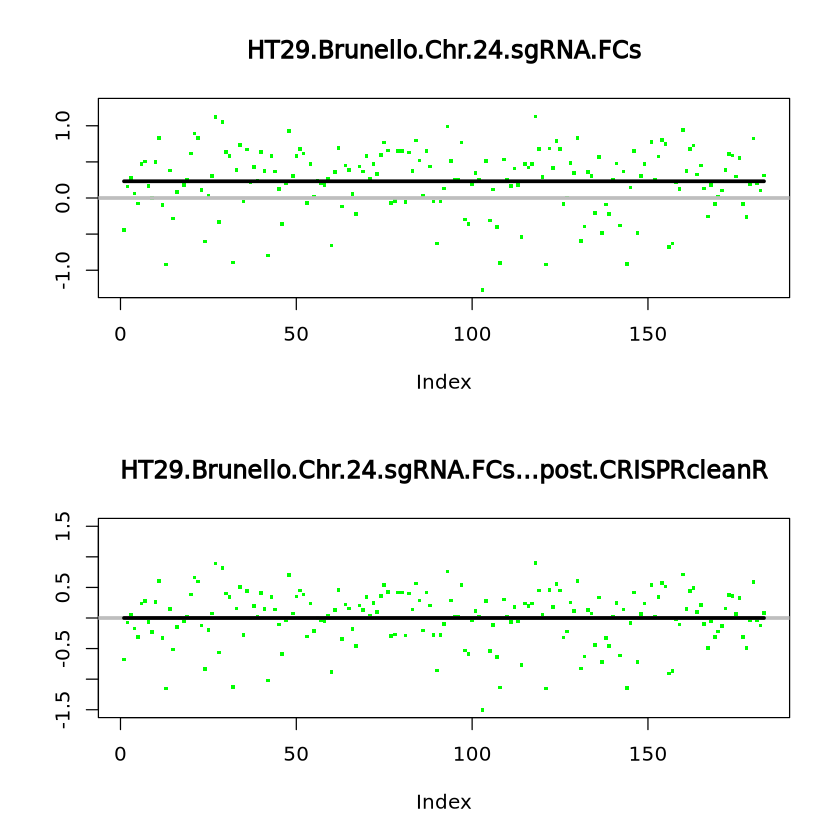

In [67]:
## Identifying and correcting biased sgRNAs' fold changes
correctedFCs_and_segments<-
ccr.GWclean(gwSortedFCs = gwSortedFCs,
display=TRUE,
label=expName)

In [68]:
## Write the corrected fold changes to file
write.csv(correctedFCs_and_segments$corrected_logFCs, file = '/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/example_Brunello/HT29_corrected_logFCs.csv')
write.csv(correctedFCs_and_segments$segments, file = '/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/example_Brunello/HT29_segments.csv')